In [1]:
from sklearn.datasets import fetch_openml
import pandas as pd

# Load the dataset
credit_data = fetch_openml(
    name="credit-g",
    version=1,
    as_frame=True
)

# Create a DataFrame
df = credit_data.frame

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (1000, 21)

Column names:
['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status', 'employment', 'installment_commitment', 'personal_status', 'other_parties', 'residence_since', 'property_magnitude', 'age', 'other_payment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone', 'foreign_worker', 'class']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  housing                 1

In [ ]:
df.isnull().sum()

,0
checking_status,0
duration,0
credit_history,0
purpose,0
credit_amount,0
savings_status,0
employment,0
installment_commitment,0
personal_status,0
other_parties,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["class"].value_counts()

,count
class,
good,700
bad,300


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

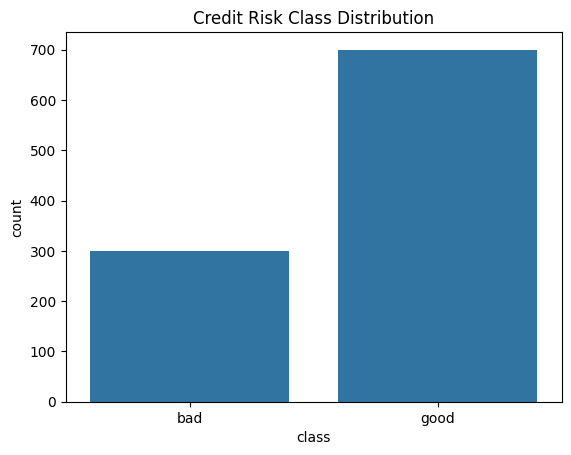

In [ ]:
sns.countplot(data=df, x="class")
plt.title("Credit Risk Class Distribution")
plt.show()

In [ ]:
df.describe(include="number").T

,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_commitment,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
num_dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


In [11]:
df.select_dtypes(include=["category", "object", "string"]).describe().T

,count,unique,top,freq
checking_status,1000,4,no checking,394
credit_history,1000,5,existing paid,530
purpose,1000,10,radio/tv,280
savings_status,1000,5,<100,603
employment,1000,5,1<=X<4,339
personal_status,1000,4,male single,548
other_parties,1000,3,none,907
property_magnitude,1000,4,car,332
other_payment_plans,1000,3,none,814
housing,1000,3,own,713


In [12]:
df["class"] = df["class"].map({"good": 1, "bad": 0})
df["class"].value_counts()

,count
class,
1,700
0,300


In [13]:
df["class"].value_counts(normalize=True) * 100

,proportion
class,
1,70.0
0,30.0


In [14]:
df["class"].value_counts()

,count
class,
1,700
0,300


In [15]:
df["class"].value_counts(normalize=True).mul(100).round(2)

,proportion
class,
1,70.0
0,30.0


In [16]:
X = df.drop(columns=["class"])
y = df["class"]

In [17]:
X.select_dtypes(include="number").columns.tolist()

['duration',
 'credit_amount',
 'installment_commitment',
 'residence_since',
 'age',
 'existing_credits',
 'num_dependents']

In [18]:
X.select_dtypes(exclude="number").columns.tolist()

['checking_status',
 'credit_history',
 'purpose',
 'savings_status',
 'employment',
 'personal_status',
 'other_parties',
 'property_magnitude',
 'other_payment_plans',
 'housing',
 'job',
 'own_telephone',
 'foreign_worker']

In [19]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (1000, 20)
Target: (1000,)


In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [23]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

In [24]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])

In [25]:
print(X_train.shape, X_test.shape)

(800, 20) (200, 20)


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [27]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
}

In [28]:
pipelines = {
    name: Pipeline([("preprocessor", preprocessor), ("model", model)])
    for name, model in models.items()
}

In [29]:
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"{name}: trained successfully")

Logistic Regression: trained successfully
Decision Tree: trained successfully
Random Forest: trained successfully


In [30]:
for name, pipe in pipelines.items():
    print(f"\n{name}")
    print(classification_report(y_test, pipe.predict(X_test), zero_division=0))


Logistic Regression
              precision    recall  f1-score   support

           0       0.47      0.70      0.56        60
           1       0.84      0.66      0.74       140

    accuracy                           0.68       200
   macro avg       0.65      0.68      0.65       200
weighted avg       0.73      0.68      0.69       200


Decision Tree
              precision    recall  f1-score   support

           0       0.46      0.73      0.56        60
           1       0.85      0.63      0.72       140

    accuracy                           0.66       200
   macro avg       0.65      0.68      0.64       200
weighted avg       0.73      0.66      0.67       200


Random Forest
              precision    recall  f1-score   support

           0       0.56      0.37      0.44        60
           1       0.76      0.88      0.82       140

    accuracy                           0.72       200
   macro avg       0.66      0.62      0.63       200
weighted avg       0.70

In [31]:
results = pd.DataFrame({
    name: {
        "Accuracy": accuracy_score(y_test, pipe.predict(X_test))
    }
    for name, pipe in pipelines.items()
}).T.sort_values("Accuracy", ascending=False)

results

,Accuracy
Random Forest,0.725
Logistic Regression,0.675
Decision Tree,0.660


In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

In [33]:
results = pd.DataFrame({
    name: {
        "Accuracy": accuracy_score(y_test, pipe.predict(X_test)),
        "Precision": precision_score(y_test, pipe.predict(X_test)),
        "Recall": recall_score(y_test, pipe.predict(X_test)),
        "F1 Score": f1_score(y_test, pipe.predict(X_test)),
        "ROC-AUC": roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    }
    for name, pipe in pipelines.items()
}).T.sort_values("ROC-AUC", ascending=False)

results.round(3)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Random Forest,0.725,0.764,0.879,0.817,0.790
Logistic Regression,0.675,0.838,0.664,0.741,0.760
Decision Tree,0.660,0.846,0.629,0.721,0.715


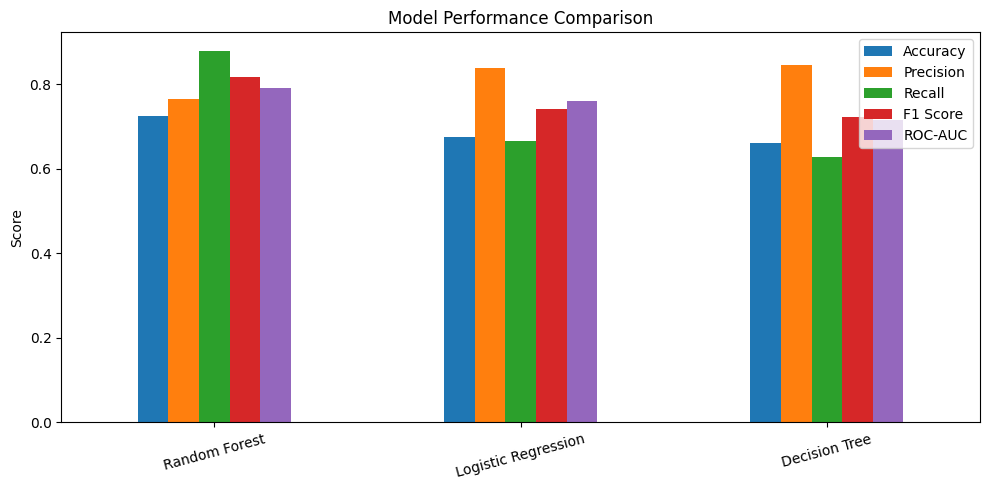

In [34]:
results.plot(kind="bar", figsize=(10, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

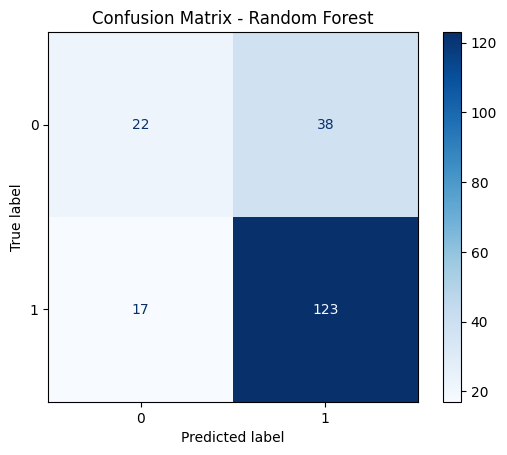

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay

best_model = pipelines[results.index[0]]
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, cmap="Blues")
plt.title(f"Confusion Matrix - {results.index[0]}")
plt.show()

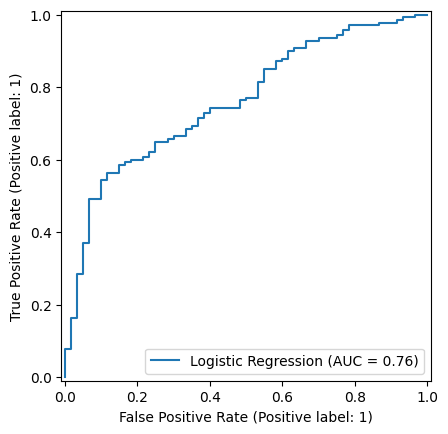

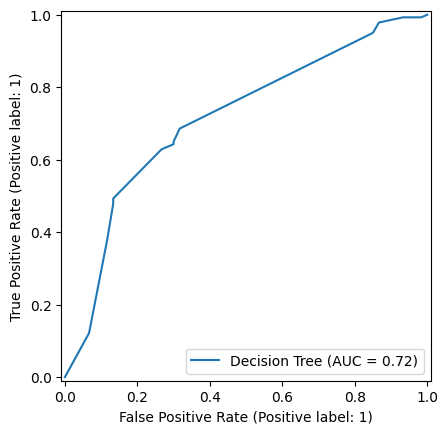

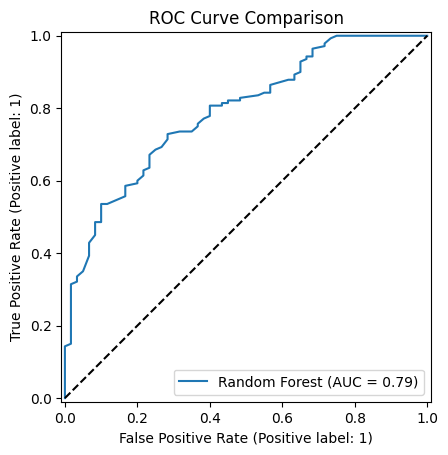

In [36]:
from sklearn.metrics import RocCurveDisplay

for name, pipe in pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name)

plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC Curve Comparison")
plt.show()

In [37]:
print("Best model:", results.index[0])
print(results.loc[results.index[0]].round(3))

Best model: Random Forest
Accuracy     0.725
Precision    0.764
Recall       0.879
F1 Score     0.817
ROC-AUC      0.790
Name: Random Forest, dtype: float64


In [38]:
from sklearn.model_selection import cross_val_score

In [39]:
cv_scores = {
    name: cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc")
    for name, pipe in pipelines.items()
}

In [40]:
pd.DataFrame({
    name: [scores.mean(), scores.std()]
    for name, scores in cv_scores.items()
}, index=["Mean ROC-AUC", "Std ROC-AUC"]).T.round(3)

,Mean ROC-AUC,Std ROC-AUC
Logistic Regression,0.784,0.042
Decision Tree,0.702,0.034
Random Forest,0.786,0.055


In [41]:
from pathlib import Path
import joblib

Path("models").mkdir(exist_ok=True)
joblib.dump(best_model, "models/credit_scoring_model.pkl")

['models/credit_scoring_model.pkl']

In [42]:
loaded_model = joblib.load("models/credit_scoring_model.pkl")
loaded_model.predict(X_test.head())

array([1, 1, 1, 1, 1])

In [43]:
predictions = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": loaded_model.predict(X_test.head(10))
})

predictions

,Actual,Predicted
0,1,1
1,1,1
2,1,1
3,1,1
4,0,1
5,1,1
6,1,1
7,0,1
8,0,1
9,1,1


In [44]:
print(y_train.value_counts())
print(y_test.value_counts())

class
1    560
0    240
Name: count, dtype: int64
class
1    140
0     60
Name: count, dtype: int64


In [45]:
print(pd.Series(best_model.predict(X_test)).value_counts())
print(results.round(3))

1    161
0     39
Name: count, dtype: int64
                     Accuracy  Precision  Recall  F1 Score  ROC-AUC
Random Forest           0.725      0.764   0.879     0.817    0.790
Logistic Regression     0.675      0.838   0.664     0.741    0.760
Decision Tree           0.660      0.846   0.629     0.721    0.715


In [46]:
pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": loaded_model.predict(X_test.iloc[:10]),
    "Probability_Good": loaded_model.predict_proba(X_test.iloc[:10])[:, 1].round(3)
})

,Actual,Predicted,Probability_Good
0,1,1,0.875
1,1,1,0.520
2,1,1,0.655
3,1,1,0.860
4,0,1,0.640
5,1,1,0.730
6,1,1,0.860
7,0,1,0.575
8,0,1,0.515
9,1,1,0.735


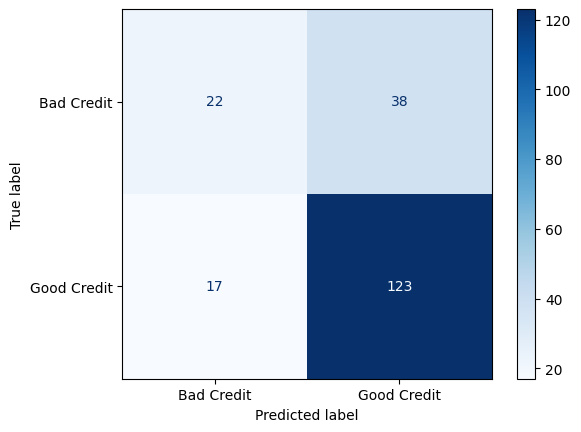

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    loaded_model, X_test, y_test,
    display_labels=["Bad Credit", "Good Credit"],
    cmap="Blues"
)
plt.show()

In [48]:
print(classification_report(
    y_test, loaded_model.predict(X_test),
    target_names=["Bad Credit", "Good Credit"]
))

              precision    recall  f1-score   support

  Bad Credit       0.56      0.37      0.44        60
 Good Credit       0.76      0.88      0.82       140

    accuracy                           0.72       200
   macro avg       0.66      0.62      0.63       200
weighted avg       0.70      0.72      0.71       200



In [49]:
from sklearn.metrics import confusion_matrix

y_prob = loaded_model.predict_proba(X_test)[:, 1]

for threshold in [0.5, 0.4, 0.3]:
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f"Threshold: {threshold} | Bad-credit recall: {tn/(tn+fp):.2f} | Accuracy: {(tn+tp)/len(y_test):.2f}")

Threshold: 0.5 | Bad-credit recall: 0.37 | Accuracy: 0.73
Threshold: 0.4 | Bad-credit recall: 0.27 | Accuracy: 0.78
Threshold: 0.3 | Bad-credit recall: 0.03 | Accuracy: 0.71


In [50]:
print(type(loaded_model.named_steps["model"]).__name__)
print(pd.Series(y_prob).describe().round(3))
print(pd.Series((y_prob >= 0.5).astype(int)).value_counts().sort_index())
print(pd.Series((y_prob >= 0.4).astype(int)).value_counts().sort_index())
print(pd.Series((y_prob >= 0.3).astype(int)).value_counts().sort_index())

RandomForestClassifier
count    200.000
mean       0.684
std        0.184
min        0.260
25%        0.560
50%        0.705
75%        0.830
max        0.995
dtype: float64
0     38
1    162
Name: count, dtype: int64
0     17
1    183
Name: count, dtype: int64
0      2
1    198
Name: count, dtype: int64


In [51]:
y_prob_bad = loaded_model.predict_proba(X_test)[:, 0]

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred = (y_prob_bad >= threshold).astype(int)
    print(f"Threshold: {threshold} | Bad-credit recall: {recall_score(y_test, y_pred, pos_label=0):.2f}")

Threshold: 0.3 | Bad-credit recall: 0.22
Threshold: 0.4 | Bad-credit recall: 0.40
Threshold: 0.5 | Bad-credit recall: 0.63
Threshold: 0.6 | Bad-credit recall: 0.73
Threshold: 0.7 | Bad-credit recall: 0.95


In [52]:
from sklearn.metrics import confusion_matrix

for threshold in [0.5, 0.6, 0.7]:
    y_pred = (y_prob_bad >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    print(f"\nThreshold: {threshold}")
    print(f"Bad Credit correctly detected: {tn}/60")
    print(f"Good Credit incorrectly flagged: {fn}/140")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")


Threshold: 0.5
Bad Credit correctly detected: 38/60
Good Credit incorrectly flagged: 123/140
Accuracy: 0.275

Threshold: 0.6
Bad Credit correctly detected: 44/60
Good Credit incorrectly flagged: 139/140
Accuracy: 0.225

Threshold: 0.7
Bad Credit correctly detected: 57/60
Good Credit incorrectly flagged: 140/140
Accuracy: 0.285


In [53]:
for threshold in [0.5, 0.6, 0.7]:
    y_pred = (y_prob_bad >= threshold).astype(int)
    y_pred = 1 - y_pred
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

    print(f"\nThreshold: {threshold}")
    print(f"Bad Credit correctly detected: {tn}/60")
    print(f"Bad Credit missed: {fp}/60")
    print(f"Good Credit incorrectly flagged: {fn}/140")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")


Threshold: 0.5
Bad Credit correctly detected: 22/60
Bad Credit missed: 38/60
Good Credit incorrectly flagged: 17/140
Accuracy: 0.725

Threshold: 0.6
Bad Credit correctly detected: 16/60
Bad Credit missed: 44/60
Good Credit incorrectly flagged: 1/140
Accuracy: 0.775

Threshold: 0.7
Bad Credit correctly detected: 3/60
Bad Credit missed: 57/60
Good Credit incorrectly flagged: 0/140
Accuracy: 0.715


In [54]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.4, 0.5, 0.6, 0.7]:
    y_pred = (y_prob_bad >= threshold).astype(int)
    y_pred = 1 - y_pred
    print(threshold,
          round(precision_score(y_test, y_pred, pos_label=0), 3),
          round(recall_score(y_test, y_pred, pos_label=0), 3),
          round(f1_score(y_test, y_pred, pos_label=0), 3))

0.4 0.571 0.6 0.585
0.5 0.564 0.367 0.444
0.6 0.941 0.267 0.416
0.7 1.0 0.05 0.095


In [55]:
thresholds = [0.4, 0.5, 0.6, 0.7]

metrics = []
for t in thresholds:
    pred = 1 - (y_prob_bad >= t).astype(int)
    metrics.append({
        "Threshold": t,
        "Bad Credit Precision": precision_score(y_test, pred, pos_label=0, zero_division=0),
        "Bad Credit Recall": recall_score(y_test, pred, pos_label=0, zero_division=0),
        "Bad Credit F1": f1_score(y_test, pred, pos_label=0, zero_division=0),
        "Accuracy": accuracy_score(y_test, pred)
    })

threshold_results = pd.DataFrame(metrics).set_index("Threshold")
threshold_results.round(3)

,Bad Credit Precision,Bad Credit Recall,Bad Credit F1,Accuracy
Threshold,,,,
0.4,0.571,0.600,0.585,0.745
0.5,0.564,0.367,0.444,0.725
0.6,0.941,0.267,0.416,0.775
0.7,1.000,0.050,0.095,0.715


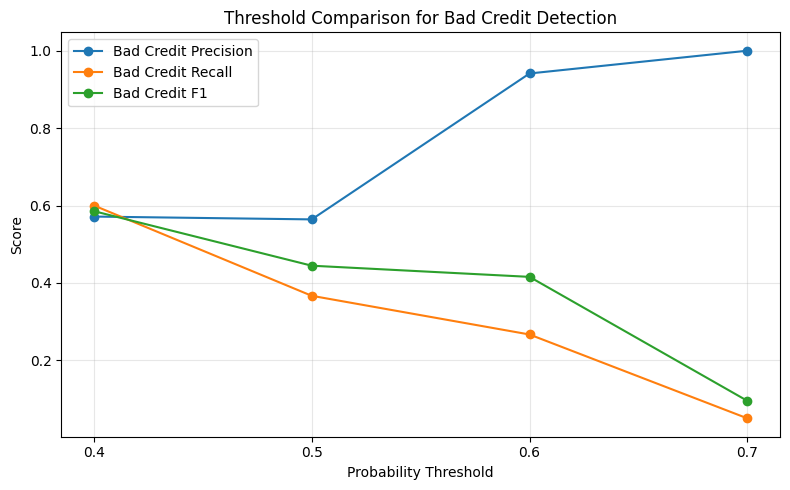

In [56]:
threshold_results[["Bad Credit Precision", "Bad Credit Recall", "Bad Credit F1"]].plot(
    marker="o", figsize=(8, 5)
)
plt.title("Threshold Comparison for Bad Credit Detection")
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.xticks(thresholds)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

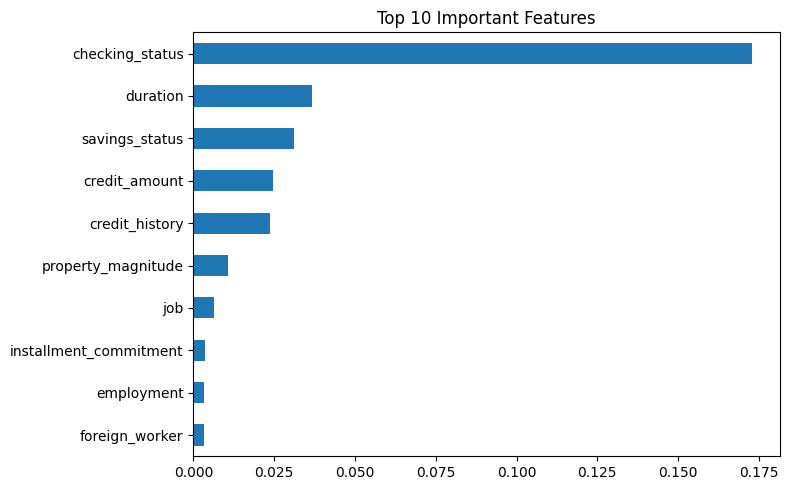

In [57]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=42
)

pd.Series(importance.importances_mean, index=X_test.columns).sort_values().tail(10).plot(
    kind="barh", figsize=(8, 5), title="Top 10 Important Features"
)
plt.tight_layout()
plt.show()

In [58]:
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)
joblib.dump(best_model, "models/credit_scoring_model.pkl")

['models/credit_scoring_model.pkl']

In [59]:
results.to_csv("model_comparison.csv")
threshold_results.to_csv("threshold_comparison.csv")

In [60]:
print("Model and evaluation results saved successfully.")

Model and evaluation results saved successfully.


In [61]:
print("Credit Scoring Model")
print("Dataset: German Credit")
print("Models: Logistic Regression, Decision Tree, Random Forest")
print("\nBest model by ROC-AUC:")
print(results.index[0])
print("\nModel comparison:")
display(results.round(3))

Credit Scoring Model
Dataset: German Credit
Models: Logistic Regression, Decision Tree, Random Forest

Best model by ROC-AUC:
Random Forest

Model comparison:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Random Forest,0.725,0.764,0.879,0.817,0.790
Logistic Regression,0.675,0.838,0.664,0.741,0.760
Decision Tree,0.660,0.846,0.629,0.721,0.715


In [62]:
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)
plt.savefig("outputs/feature_importance.png", dpi=300, bbox_inches="tight")
results.to_csv("outputs/model_comparison.csv")
threshold_results.to_csv("outputs/threshold_comparison.csv")

<Figure size 640x480 with 0 Axes>